In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold

## Data generation

In [2]:
def generate_data(n, seed):
    rng = np.random.default_rng(seed)
    x = rng.uniform(-1.0, 1.0, size=n)
    noise = rng.normal(0.0, 0.3, size=n)
    y = 1.0 + 2.0 * x - 3.0 * x**2 + noise
    return x, y

x_dev, y_dev = generate_data(n=600, seed=2026)
x_test, y_test = generate_data(n=200, seed=2027)

def make_poly_features(x, degree):
    return np.column_stack([x**p for p in range(1, degree + 1)])

print(f"Data dev: {len(x_dev)} sample | Data test: {len(x_test)} sample")

Data dev: 600 sample | Data test: 200 sample


## Comparing polynomial degrees with OLS


In [3]:
degrees_ols = [1, 2, 3, 5, 8, 12]
ols_train_mse = {}

for m in degrees_ols:
    X_train = make_poly_features(x_dev, m)
    model = LinearRegression(fit_intercept=True)
    model.fit(X_train, y_dev)
    pred = model.predict(X_train)
    ols_train_mse[m] = mean_squared_error(y_dev, pred)

for m, mse in ols_train_mse.items():
    print(f"Degree {m:2d}: {mse:.6f}")

Degree  1: 0.875315
Degree  2: 0.083446
Degree  3: 0.083374
Degree  5: 0.083182
Degree  8: 0.081730
Degree 12: 0.080951


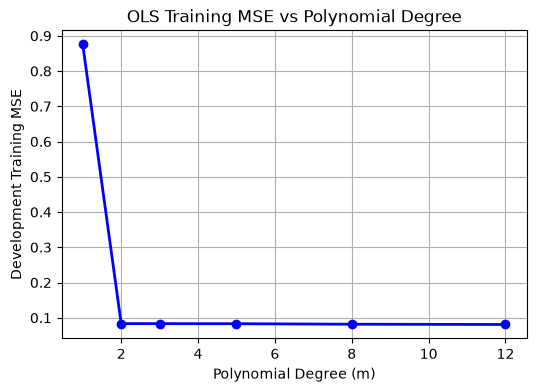

In [4]:
plt.figure(figsize=(6, 4))
plt.plot(degrees_ols, [ols_train_mse[m] for m in degrees_ols], marker='o', linewidth=2, color='b')
plt.xlabel('Polynomial Degree (m)')
plt.ylabel('Development Training MSE')
plt.title('OLS Training MSE vs Polynomial Degree')
plt.grid(True)
plt.show()

## Ridge Regression 

In [5]:
lambdas = [1e-4, 1e-3, 1e-2, 1e-1]
X_dev_12 = make_poly_features(x_dev, 12)
N_dev = len(x_dev)

# Baseline: Degree-12 OLS
ols_12 = LinearRegression(fit_intercept=True).fit(X_dev_12, y_dev)
ols_12_mse = mean_squared_error(y_dev, ols_12.predict(X_dev_12))
ols_12_norm = np.linalg.norm(ols_12.coef_)

ridge_results = {'OLS (baseline)': {'mse': ols_12_mse, 'norm': ols_12_norm}}

for lam in lambdas:
    model = Ridge(alpha=N_dev * lam, fit_intercept=True)
    model.fit(X_dev_12, y_dev)
    mse = mean_squared_error(y_dev, model.predict(X_dev_12))
    norm = np.linalg.norm(model.coef_)
    ridge_results[lam] = {'mse': mse, 'norm': norm}

print(f"Baseline OLS: MSE = {ols_12_mse:.6f}, Norm = {ols_12_norm:.6f}")
for lam in lambdas:
    print(f"lambda = {lam:6.4f}: MSE = {ridge_results[lam]['mse']:.6f}, Norm = {ridge_results[lam]['norm']:.6f}")

Baseline OLS: MSE = 0.080951, Norm = 217.407182
lambda = 0.0001: MSE = 0.082419, Norm = 3.859212
lambda = 0.0010: MSE = 0.083659, Norm = 3.244695
lambda = 0.0100: MSE = 0.097168, Norm = 2.743050
lambda = 0.1000: MSE = 0.263926, Norm = 1.764355


## Lasso Regression and Sparsity 


In [6]:
lasso_results = {}
for lam in lambdas:
    model = Lasso(alpha=lam, fit_intercept=True, max_iter=100000, tol=1e-6)
    model.fit(X_dev_12, y_dev)
    mse = mean_squared_error(y_dev, model.predict(X_dev_12))
    coef = model.coef_
    nonzero_idx = [p + 1 for p, val in enumerate(coef) if abs(val) > 1e-6]
    lasso_results[lam] = {
        'mse': mse,
        'num_nonzero': len(nonzero_idx),
        'powers': nonzero_idx
    }

for lam in lambdas:
    res = lasso_results[lam]
    print(f"lambda = {lam:6.4f}: MSE = {res['mse']:.6f}, Nonzero = {res['num_nonzero']}, Powers = {res['powers']}")

lambda = 0.0001: MSE = 0.082779, Nonzero = 6, Powers = [1, 2, 5, 8, 11, 12]
lambda = 0.0010: MSE = 0.083151, Nonzero = 4, Powers = [1, 2, 6, 11]
lambda = 0.0100: MSE = 0.084971, Nonzero = 2, Powers = [1, 2]
lambda = 0.1000: MSE = 0.235964, Nonzero = 2, Powers = [1, 2]


## Five-Fold Cross-Validation and Final Evaluation

In [7]:
candidates = []

# 6 OLS candidates
for m in degrees_ols:
    candidates.append(('OLS', m, 0.0))
# 4 Ridge candidates (m=12)
for lam in lambdas:
    candidates.append(('Ridge', 12, lam))
# 4 Lasso candidates (m=12)
for lam in lambdas:
    candidates.append(('Lasso', 12, lam))

kf = KFold(n_splits=5, shuffle=True, random_state=3020)
cv_results = []
N_train_fold = 480

for family, m, lam in candidates:
    fold_mses = []
    for train_idx, val_idx in kf.split(x_dev):
        x_tr, y_tr = x_dev[train_idx], y_dev[train_idx]
        x_vl, y_vl = x_dev[val_idx], y_dev[val_idx]

        X_tr = make_poly_features(x_tr, m)
        X_vl = make_poly_features(x_vl, m)

        if family == 'OLS':
            clf = LinearRegression(fit_intercept=True)
        elif family == 'Ridge':
            clf = Ridge(alpha=N_train_fold * lam, fit_intercept=True)
        elif family == 'Lasso':
            clf = Lasso(alpha=lam, fit_intercept=True, max_iter=100000, tol=1e-6)

        clf.fit(X_tr, y_tr)
        val_pred = clf.predict(X_vl)
        fold_mses.append(mean_squared_error(y_vl, val_pred))

    mean_mse = np.mean(fold_mses)
    cv_results.append({
        'family': family,
        'degree': m,
        'lambda': lam,
        'fold_mses': fold_mses,
        'mean_mse': mean_mse
    })

family_rank = {'OLS': 0, 'Ridge': 1, 'Lasso': 2}
cv_results.sort(key=lambda r: (round(r['mean_mse'], 8), r['degree'], family_rank[r['family']], r['lambda']))

for r in cv_results:
    mses_str = " ".join([f"{v:.6f}" for v in r['fold_mses']])
    print(f"{r['family']:5s} (m={r['degree']:2d}, lam={r['lambda']:<6}): Folds=[{mses_str}] | Mean={r['mean_mse']:.6f}")

selected = cv_results[0]
print(f"Selected Candidate: Family = {selected['family']}, Degree = {selected['degree']}, lambda = {selected['lambda']}")

# Refit on all 600 development samples (N=600)
X_dev_sel = make_poly_features(x_dev, selected['degree'])
X_test_sel = make_poly_features(x_test, selected['degree'])

if selected['family'] == 'OLS':
    final_model = LinearRegression(fit_intercept=True)
elif selected['family'] == 'Ridge':
    final_model = Ridge(alpha=N_dev * selected['lambda'], fit_intercept=True)
elif selected['family'] == 'Lasso':
    final_model = Lasso(alpha=selected['lambda'], fit_intercept=True, max_iter=100000, tol=1e-6)

final_model.fit(X_dev_sel, y_dev)
test_pred = final_model.predict(X_test_sel)
test_mse = mean_squared_error(y_test, test_pred)

print(f"Final Test MSE on 200 samples: {test_mse:.6f}")

OLS   (m= 2, lam=0.0   ): Folds=[0.090427 0.064127 0.089909 0.083017 0.093588] | Mean=0.084214
OLS   (m= 3, lam=0.0   ): Folds=[0.090292 0.064229 0.089753 0.083419 0.093731] | Mean=0.084285
OLS   (m= 8, lam=0.0   ): Folds=[0.089137 0.065573 0.093077 0.082603 0.091279] | Mean=0.084334
Lasso (m=12, lam=0.001 ): Folds=[0.090016 0.064542 0.089920 0.084019 0.093970] | Mean=0.084493
Ridge (m=12, lam=0.0001): Folds=[0.090156 0.064607 0.090694 0.084552 0.093094] | Mean=0.084620
OLS   (m=12, lam=0.0   ): Folds=[0.088964 0.065312 0.094578 0.082781 0.092215] | Mean=0.084770
Lasso (m=12, lam=0.0001): Folds=[0.090225 0.064841 0.090532 0.084482 0.093904] | Mean=0.084797
OLS   (m= 5, lam=0.0   ): Folds=[0.090692 0.064682 0.089964 0.084374 0.094842] | Mean=0.084911
Ridge (m=12, lam=0.001 ): Folds=[0.091850 0.064519 0.091008 0.086824 0.093246] | Mean=0.085489
Lasso (m=12, lam=0.01  ): Folds=[0.091624 0.063574 0.089591 0.083788 0.100725] | Mean=0.085860
Ridge (m=12, lam=0.01  ): Folds=[0.105959 0.078307